# Tema 28 · Audio: del sonido a los números

Ondas, espectrogramas y modelos que escuchan y transcriben.

Este cuaderno es el tema 28 de la [ruta de aprendizaje de la OBIA](https://iabolivia.org/aprende/aprendizaje-automatico/): la teoría y los ejercicios de [la página del tema](https://iabolivia.org/aprende/aprendizaje-automatico/28-audio-del-sonido-a-los-numeros/), con todo su código. Ejecuta las celdas en orden, de arriba abajo (o *Entorno de ejecución → Ejecutar todas*).

Debajo de cada celda está la salida que dio cuando se escribió el tema. Al ejecutarla, la tuya puede variar en los últimos decimales. Las actividades interactivas están en la página del tema.

Este tema entrena o usa redes grandes: en Colab, *Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU* lo hace mucho más rápido.

Primero, las bibliotecas que este tema necesita y que Colab no trae (o trae en otra versión):

In [ ]:
!pip install -q accelerate==1.15.0 jiwer==4.0.0 soundfile==0.14.0 transformers==5.21.0 umap-learn==0.5.12

# Teoría

## La pregunta

Le dices a tu celular «pon música» y lo hace. Pero un micrófono no entrega palabras: entrega una presión de aire que sube y baja miles de veces por segundo. ¿Cómo se pasa de esa vibración a números que una red pueda leer, y de esos números a un texto escrito?

En este tema vas a:

- leer un audio en Python, entender la **frecuencia de muestreo** y dibujar la **onda**;
- descomponer un sonido en frecuencias con la **transformada de Fourier** y armar un **espectrograma**, normal y de **Mel**, sabiendo qué dice cada eje;
- clasificar dígitos hablados con una **CNN sobre espectrogramas** (el tema 20) y con **embeddings de HuBERT** (el tema 22);
- transcribir audio en español con **Whisper** y medir sus errores con la **tasa de error de palabras** (WER), con y sin ruido;
- saber qué son los modelos de **audio y lenguaje**, como Qwen-Audio y Voxtral, y cuándo conviene usarlos.

Necesitas lo del tema 20 (convoluciones y la función `entrenar` del tema 18), lo del tema 22 (embeddings y UMAP) y lo de los temas 23 a 25 (transformers, codificador-decodificador y el LLM Qwen del tema 24).

## Actividad: mira tu voz

Antes de cualquier fórmula, mira un sonido. Arriba se dibuja la **onda**: cuánto se mueve la membrana del micrófono en cada instante. Abajo, el **espectrograma**: lo nuevo aparece a la derecha y se va corriendo hacia la izquierda (como en las figuras del tema, el tiempo avanza de izquierda a derecha), la altura es la frecuencia (grave abajo, agudo arriba) y cuanto más oscura la tinta, más fuerte suena esa frecuencia en ese momento.

> **Actividad interactiva:** está en la [página del tema](https://iabolivia.org/aprende/aprendizaje-automatico/28-audio-del-sonido-a-los-numeros/teoria/). Ábrela en el navegador para usarla.
Prueba esto, en orden:

1. Pulsa «Tono» y mueve la frecuencia. Una sola frecuencia es **una sola raya horizontal**. ¿Qué le pasa a la raya cuando subes el tono? ¿Y a la onda?
2. Pulsa «Mezcla»: suenan tres notas a la vez y un silbido que sube. Cuenta las rayas. La onda se ve enredada, pero el espectrograma separa cada ingrediente.
3. Si quieres, pulsa «Grabar» y di «aaa» con voz grave y después aguda. Tu voz no es una raya: es una **escalera de rayas** paralelas (los armónicos). Ahora di «sss»: es una mancha arriba, sin rayas.
4. Mueve el tamaño de la FFT. Con un tamaño chico las rayas se ven gruesas pero los cambios rápidos se ven nítidos; con uno grande, al revés. Vas a ver por qué en la sección sobre la ventana.

La idea de todo el tema: **un sonido es una mezcla de frecuencias, y el espectrograma es su partitura**. Una partitura es una imagen, y a las imágenes ya sabes enseñarles a una CNN.

## Leer un audio

Vamos a usar un audio de verdad: el comienzo del capítulo I de *Don Quijote*, leído por Nessi para [LibriVox](https://librivox.org/don-quijote-vol-1-by-miguel-de-cervantes-saavedra/), un proyecto de voluntarios que graba libros en **dominio público**. El código baja el capítulo completo de [archive.org](https://archive.org/details/don_quijote_vol1_0706_librivox) la primera vez (21 MB) y se queda con 55 segundos, desde «En un lugar de la Mancha» hasta «como tomaba la podadera».

Para leer audio usamos `soundfile`. `torchaudio` también tenía una función `load`, pero desde la versión 2.9 necesita otro paquete, `torchcodec`, que depende de programas de video instalados aparte; por eso aquí leemos con `soundfile` y usamos `torchaudio` solo para transformar.

In [ ]:
import re
import tarfile
import textwrap
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import soundfile as sf
import torch
import torchaudio
from torch import nn

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
DATOS = Path("datos")


def bajar(url, destino):
    """Baja un archivo de internet, solo si todavía no está."""
    destino = Path(destino)
    if not destino.exists():
        destino.parent.mkdir(parents=True, exist_ok=True)
        pedido = urllib.request.Request(
            url, headers={"User-Agent": "ruta-obia/1.0 (curso de IA)"})
        with urllib.request.urlopen(pedido) as respuesta:
            destino.write_bytes(respuesta.read())
    return destino


# Don Quijote, cap. I, leído por Nessi para LibriVox (dominio público)
wav = DATOS / "audio-ruta/quijote-cap1-55s-16k.wav"
if not wav.exists():
    url = ("https://archive.org/download/don_quijote_vol1_0706_librivox/"
           "quijote_vol1_03_cervantes_64kb.mp3")
    mp3 = bajar(url, DATOS / "audio-ruta/quijote-vol1-03-librivox.mp3")
    # Del segundo 36,0 al 90,8: antes viene el aviso de LibriVox
    trozo, sr_mp3 = sf.read(mp3, dtype="float32",
                            start=int(36.0 * 22050),
                            stop=int(90.8 * 22050))
    trozo = torchaudio.functional.resample(torch.from_numpy(trozo),
                                           sr_mp3, 16000)
    sf.write(wav, trozo.numpy(), 16000)

onda, sr = sf.read(wav, dtype="float32")
print("Forma:", onda.shape, "  tipo:", onda.dtype)
print("Frecuencia de muestreo:", sr, "muestras por segundo")
print(f"Duración: {len(onda) / sr:.1f} s")
print("Seis muestras seguidas:", np.round(onda[16000:16006], 3))

Forma: (876800,)   tipo: float32
Frecuencia de muestreo: 16000 muestras por segundo
Duración: 54.8 s
Seis muestras seguidas: [-0.098 -0.134 -0.171 -0.21  -0.227 -0.235]


Un audio digital es **un vector de números**. Cada número es una **muestra**: cuánto estaba desplazada la membrana del micrófono en ese instante, entre −1 y 1. La **frecuencia de muestreo** (*sample rate*, `sr`) dice cuántas muestras se toman por segundo: aquí 16 000, que es lo que esperan los modelos de voz de este tema. Un CD usa 44 100. Con eso, la duración es simplemente la cantidad de muestras dividida entre `sr`.

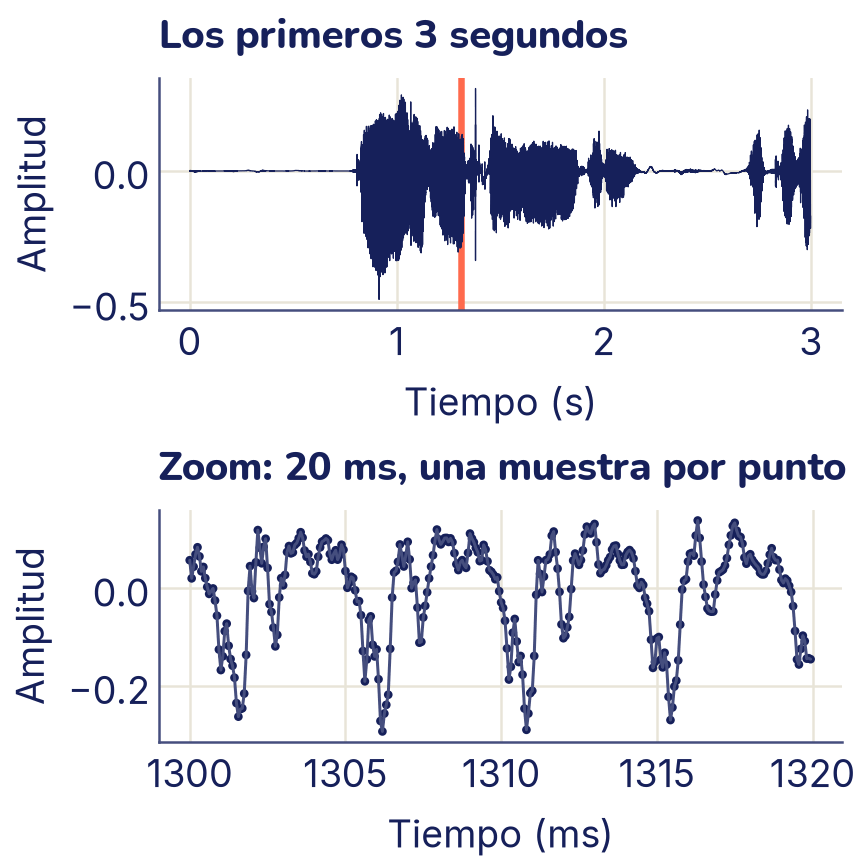

In [ ]:
t = np.arange(len(onda)) / sr              # el tiempo de cada muestra
tres = t < 3
zoom = (t >= 1.30) & (t < 1.32)            # 20 milisegundos

fig, (arriba, abajo) = plt.subplots(2, 1, figsize=(4.8, 4.8))
arriba.plot(t[tres], onda[tres], color="C0", linewidth=0.5)
arriba.axvspan(1.30, 1.32, color="C1")
arriba.set_xlabel("Tiempo (s)")
arriba.set_ylabel("Amplitud")
arriba.set_title("Los primeros 3 segundos")
abajo.plot(t[zoom] * 1000, onda[zoom], color="C2", linewidth=1.2)
abajo.scatter(t[zoom] * 1000, onda[zoom], s=12, color="C0",
              edgecolors="none")
abajo.set_xlabel("Tiempo (ms)")
abajo.set_ylabel("Amplitud")
abajo.set_title("Zoom: 20 ms, una muestra por punto")
plt.show()

De lejos, la voz son ráfagas: cada sílaba sonora es un golpe de amplitud, y los silencios son tramos planos. De cerca, dentro de una vocal, la onda **se repite**: en el zoom, el mismo dibujo aparece cuatro veces en 20 ms, unas 200 veces por segundo. Esa repetición es lo que oímos como el tono de la voz. Fíjate que cada punto del zoom es una muestra: entre punto y punto no hay nada guardado.

### Muestrear: ¿cuántas muestras hacen falta?

Un tono puro es un seno o un coseno. `np.sin(2 * np.pi * f * t)` da *f* vueltas completas por segundo: el 2π es una vuelta entera medida en radianes, así que cuando *t* avanza 1/*f* de segundo, lo de adentro avanza 2π y la onda se repite. Por eso se dice que el seno «vibra *f* veces por segundo» y que su **frecuencia** es *f* hercios (Hz).

Si se toman pocas muestras por segundo, una vibración rápida se puede confundir con una lenta. Mira un tono de 900 Hz (900 vibraciones por segundo) medido de dos formas:

True


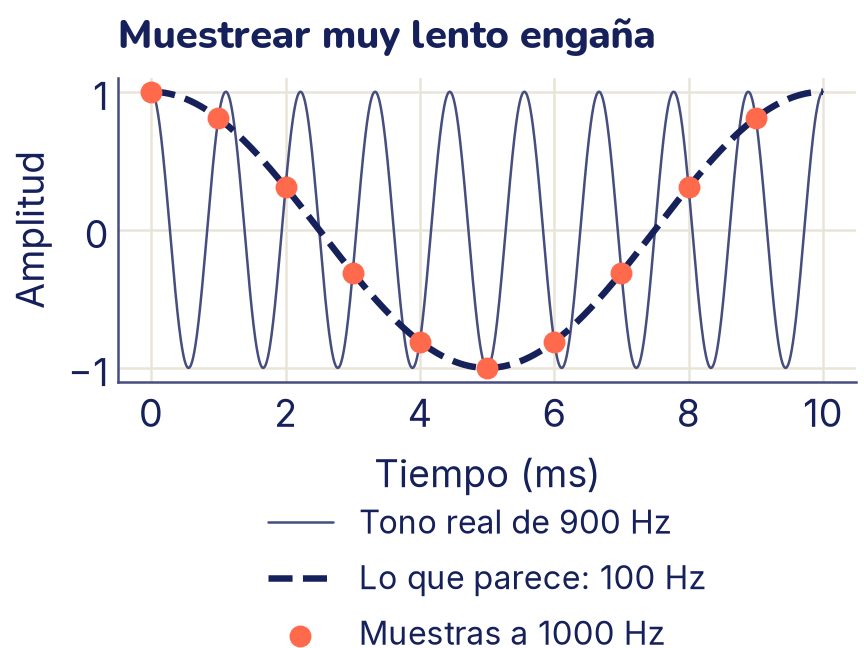

In [ ]:
f_tono = 900
t_fino = np.linspace(0, 0.01, 2000)        # «continuo»: 10 ms
t_lento = np.arange(0, 0.01, 1 / 1000)     # 1000 muestras por segundo

# Un poco más alta, para que quepa la leyenda de abajo
plt.figure(figsize=(4.8, 3.6))
plt.plot(t_fino * 1000, np.cos(2 * np.pi * f_tono * t_fino),
         color="C2", linewidth=1, label="Tono real de 900 Hz")
plt.plot(t_fino * 1000, np.cos(2 * np.pi * 100 * t_fino),
         color="C0", linestyle="--", label="Lo que parece: 100 Hz")
plt.scatter(t_lento * 1000, np.cos(2 * np.pi * f_tono * t_lento),
            color="C1", s=60, zorder=3, label="Muestras a 1000 Hz")
plt.xlabel("Tiempo (ms)")
plt.ylabel("Amplitud")
plt.title("Muestrear muy lento engaña")
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.3), fontsize=13)
plt.show()

# ¿Las muestras de 900 Hz y de 100 Hz son las mismas?
n = np.arange(1000)
print(np.allclose(np.cos(2 * np.pi * 900 * n / 1000),
                  np.cos(2 * np.pi * 100 * n / 1000)))

Con 1000 muestras por segundo, las muestras de un tono de 900 Hz son **exactamente** las mismas que las de uno de 100 Hz: después de muestrear ya no hay forma de distinguirlos. Este engaño se llama ***aliasing***. La regla que lo evita es el **criterio de Nyquist**: con `sr` muestras por segundo solo se pueden representar bien las frecuencias de hasta `sr / 2`. Esa mitad se llama **frecuencia de Nyquist**. A 16 000 Hz llegamos hasta 8000 Hz, suficiente para entender la voz; a 44 100 Hz, hasta 22 050 Hz, un poco más de lo que oye una persona joven.

## De la onda a las frecuencias

La onda dice cuánto se movió la membrana en cada instante, pero no dice **qué notas** suenan. La **transformada de Fourier** responde eso: toma una señal y la escribe como suma de senos de distintas frecuencias, y dice cuánto pesa cada uno. Para probarla, armamos una mezcla de la que sabemos la respuesta: tres tonos de 220, 440 y 660 Hz, con amplitudes 1, 0,5 y 0,25, más un poco de ruido. Son datos **sintéticos**: los inventamos para comprobar que el método los encuentra.

Muestras: 8000   frecuencias: 4001
De 0 a 4000 Hz, cada 1 Hz
  220 Hz: amplitud 1.00
  440 Hz: amplitud 0.50
  660 Hz: amplitud 0.25


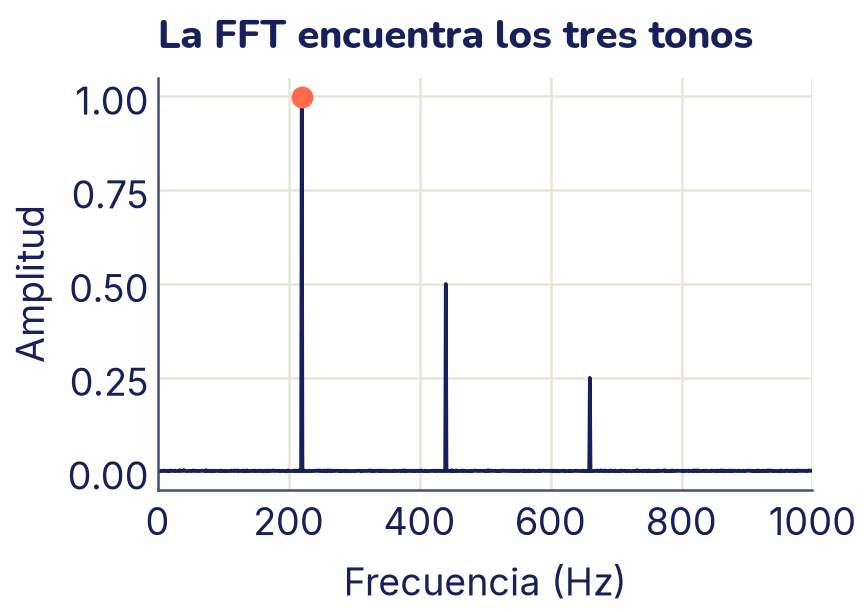

In [ ]:
sr_m = 8000
t1 = np.arange(sr_m) / sr_m                # un segundo
rng = np.random.default_rng(0)
mezcla = (1.0 * np.sin(2 * np.pi * 220 * t1)
          + 0.5 * np.sin(2 * np.pi * 440 * t1)
          + 0.25 * np.sin(2 * np.pi * 660 * t1)
          + 0.05 * rng.normal(size=sr_m))

espectro = np.fft.rfft(mezcla)             # números complejos
frecuencias = np.fft.rfftfreq(len(mezcla), d=1 / sr_m)
amplitud = 2 * np.abs(espectro) / len(mezcla)
print("Muestras:", len(mezcla), "  frecuencias:", len(espectro))
print(f"De {frecuencias[0]:.0f} a {frecuencias[-1]:.0f} Hz, "
      f"cada {frecuencias[1]:.0f} Hz")
for i in np.argsort(amplitud)[::-1][:3]:
    print(f"{frecuencias[i]:5.0f} Hz: amplitud {amplitud[i]:.2f}")

plt.plot(frecuencias, amplitud, color="C0", linewidth=1.5)
plt.scatter([220], [amplitud[220]], color="C1", s=60, zorder=3)
plt.xlim(0, 1000)
plt.xlabel("Frecuencia (Hz)")
plt.ylabel("Amplitud")
plt.title("La FFT encuentra los tres tonos")
plt.show()

`np.fft.rfft` calcula la transformada de Fourier con el algoritmo rápido **FFT** (*Fast Fourier Transform*). La «r» es de *real*: como el audio son números reales, basta con la mitad del espectro, de 0 Hz a la frecuencia de Nyquist. Con 8000 muestras salen 4001 frecuencias, espaciadas cada `sr / N` = 1 Hz. ¿Cómo «encuentra» las frecuencias? La idea es la del producto punto del tema 3: la FFT compara la señal con un seno de cada frecuencia, y si se parecen, el resultado es grande; si no, se cancela y da casi cero. Cada resultado es un **número complejo**, que en la práctica es un par de números: cuánto pesa ese seno y dónde empieza su onda (su desfase). `np.abs` se queda con el primero; escalado por 2/N, es la amplitud de ese seno. Los tres picos salen en su lugar y con su altura, y el ruido queda como una alfombra casi plana.

## El espectrograma: Fourier por pedacitos

Una sola FFT de 55 segundos de lectura diría qué frecuencias aparecen **en algún momento**, pero no **cuándo**. La solución es cortar el audio en ventanas cortas que se pisan entre sí, multiplicar cada una por una campana que suaviza los bordes (la ventana de Hann, para que el corte brusco al principio y al final de la ventana no aparezca como frecuencias falsas) y hacer una FFT por ventana. Eso es la **transformada de Fourier de tiempo corto** o **STFT**. Pones los espectros uno al lado del otro, como columnas, y tienes un **espectrograma**: el tiempo en el eje horizontal, la frecuencia en el vertical y la intensidad como tinta.

Dos números la controlan:

- el **tamaño de la ventana** (`n_fft`): cuántas muestras entran en cada FFT;
- el **salto** (`salto`, en inglés *hop length*): cuántas muestras se avanza de una ventana a la siguiente.

In [ ]:
def stft(senal, n_fft, salto):
    """Magnitud de la STFT: una columna por ventana."""
    hann = np.hanning(n_fft)
    inicios = range(0, len(senal) - n_fft + 1, salto)
    cuadros = np.array([senal[i:i + n_fft] * hann for i in inicios])
    return np.abs(np.fft.rfft(cuadros, axis=1)).T   # (frec., tiempo)


def en_db(magnitud):
    """Decibeles: 20·log10 de la amplitud, con un piso para no tomar
    log de 0."""
    return 20 * np.log10(np.maximum(magnitud, 1e-4))

Los **decibeles** (dB) son una escala logarítmica para comparar intensidades: cada 10 dB más es 10 veces más potencia, y 20 dB más, 100 veces (log10 cuenta cuántas veces se multiplica por 10). La potencia es la amplitud al cuadrado, y 10 · log10(*A*²) = 20 · log10(*A*): por eso, para amplitudes como las de la STFT, `en_db` usa 20 · log10, y para potencias se usa 10 · log10.

¿Qué tamaño de ventana conviene? Para verlo, otra señal sintética de 1 segundo con dos cosas difíciles a la vez: **dos tonos muy cercanos** (500 y 560 Hz, sonando juntos todo el tiempo) y **tres chasquidos** de un milisegundo en 0,25, 0,5 y 0,75 s.

n_fft =   64: ventana de   8.0 ms, una fila cada 125.00 Hz
n_fft =  256: ventana de  32.0 ms, una fila cada  31.25 Hz
n_fft = 2048: ventana de 256.0 ms, una fila cada   3.91 Hz


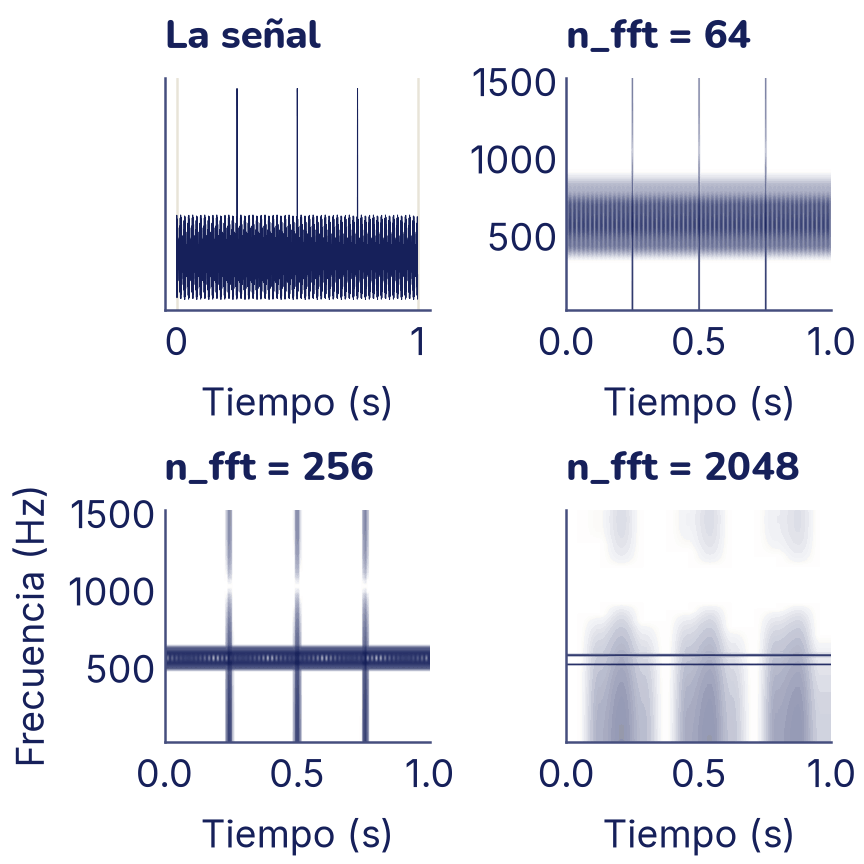

In [ ]:
from matplotlib.colors import LinearSegmentedColormap

tinta = LinearSegmentedColormap.from_list("tinta", ["white", "C0"])

senal = np.sin(2 * np.pi * 500 * t1) + np.sin(2 * np.pi * 560 * t1)
for inicio in [0.25, 0.5, 0.75]:
    i = int(inicio * sr_m)
    senal[i:i + 8] += 6                    # un chasquido de 1 ms

fig, ejes = plt.subplots(2, 2, figsize=(4.8, 4.8))
ejes[0, 0].plot(t1, senal, color="C0", linewidth=0.4)
ejes[0, 0].set_title("La señal")
ejes[0, 0].set_xlabel("Tiempo (s)")
for eje, n_fft in zip(ejes.flat[1:], [64, 256, 2048]):
    S = en_db(stft(senal, n_fft, n_fft // 4))
    eje.imshow(S, origin="lower", aspect="auto", cmap=tinta,
               vmin=S.max() - 40, extent=[0, 1, 0, sr_m / 2])
    eje.set_ylim(0, 1500)
    eje.set_yticks([500, 1000, 1500])
    eje.set_title(f"n_fft = {n_fft}")
    eje.set_xlabel("Tiempo (s)")
    eje.grid(False)
ejes[0, 0].set_yticks([])
ejes[1, 1].set_yticklabels([])
ejes[1, 0].set_ylabel("Frecuencia (Hz)")
plt.show()

for n_fft in [64, 256, 2048]:
    print(f"n_fft = {n_fft:4}: ventana de {1000 * n_fft / sr_m:5.1f} ms,"
          f" una fila cada {sr_m / n_fft:6.2f} Hz")

Es un **compromiso que no se puede evitar**: una ventana larga mira mucho tiempo y distingue frecuencias cercanas (una fila cada 3,9 Hz con 2048 muestras), pero mezcla todo lo que pasó dentro de sus 256 ms, así que los chasquidos se desparraman. Una ventana corta ubica muy bien los chasquidos, pero sus filas están a 125 Hz de distancia y los dos tonos caen en la misma. Para la voz se usan ventanas de unos 25 ms con un salto de 10 ms, que es lo que hacen Whisper y casi todos los modelos de habla.

### El espectrograma de Mel

El oído no trata igual todas las frecuencias: entre 200 y 400 Hz oímos un salto enorme (una octava), pero entre 7200 y 7400 Hz casi no notamos la diferencia. La **escala de Mel** imita eso: estira las frecuencias graves y aprieta las agudas. La fórmula más usada es

$$m = 2595 \cdot {\log}_{10} ( 1 + \frac{f}{700} )$$

donde *f* está en Hz y *m* en mels. Un **espectrograma de Mel** agrupa las filas de la STFT en unas pocas bandas (40, 64 u 80) igual de anchas **en mels**: muchas bandas finas en los graves y pocas anchas en los agudos. Después se toma el logaritmo (el **log-Mel**), porque el oído también percibe la intensidad en escala logarítmica. `torchaudio` hace todo eso en una línea.

  250 Hz ->    344 mels
  500 Hz ->    607 mels
 1000 Hz ->   1000 mels
 2000 Hz ->   1521 mels
 4000 Hz ->   2146 mels
 8000 Hz ->   2840 mels
STFT: (201, 298)   Mel: (64, 301)


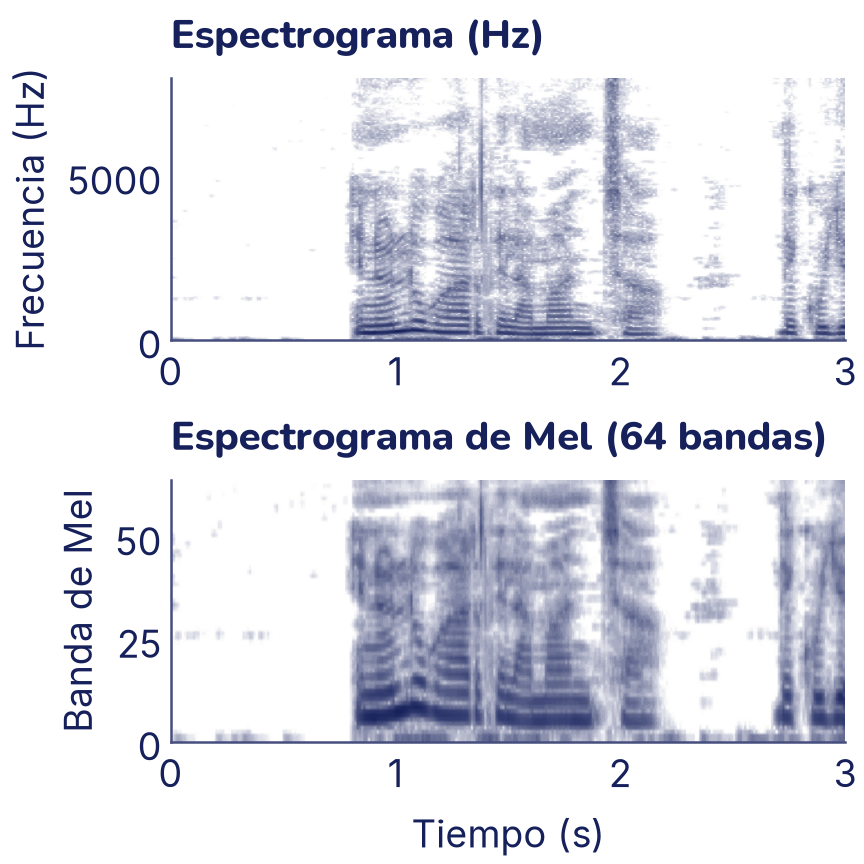

In [ ]:
for f in [250, 500, 1000, 2000, 4000, 8000]:
    print(f"{f:5} Hz -> {2595 * np.log10(1 + f / 700):6.0f} mels")

a_mel = torchaudio.transforms.MelSpectrogram(
    sample_rate=sr, n_fft=400, hop_length=160, n_mels=64)
a_db = torchaudio.transforms.AmplitudeToDB()
voz = onda[:3 * sr]                        # los primeros 3 segundos
S_lineal = en_db(stft(voz, 400, 160))
S_mel = a_db(a_mel(torch.from_numpy(voz))).numpy()
print("STFT:", S_lineal.shape, "  Mel:", S_mel.shape)

fig, (arriba, abajo) = plt.subplots(2, 1, figsize=(4.8, 4.8))
arriba.imshow(S_lineal, origin="lower", aspect="auto", cmap=tinta,
              vmin=S_lineal.max() - 70, extent=[0, 3, 0, sr / 2])
arriba.set_title("Espectrograma (Hz)")
arriba.set_ylabel("Frecuencia (Hz)")
abajo.imshow(S_mel, origin="lower", aspect="auto", cmap=tinta,
             vmin=S_mel.max() - 70, extent=[0, 3, 0, 64])
abajo.set_title("Espectrograma de Mel (64 bandas)")
abajo.set_ylabel("Banda de Mel")
abajo.set_xlabel("Tiempo (s)")
for eje in (arriba, abajo):
    eje.grid(False)
plt.show()

Las dos imágenes muestran lo mismo, con otra regla vertical. En la de arriba, casi todo lo interesante de la voz se amontona en el cuarto de abajo; en la de Mel, los graves, donde están las vocales y el tono, ocupan buena parte de la imagen. Fíjate en lo que se ve:

- Las **vocales** son escaleras de rayas horizontales paralelas: la de más abajo es el tono de la voz y las demás, sus **armónicos** (múltiplos de esa frecuencia). Es lo que viste en la actividad al decir «aaa».
- Las **consonantes** como la «s» o la «ch» son manchas verticales que llegan alto: ruido sin tono, repartido en muchas frecuencias.
- Los **silencios** son columnas en blanco.

La forma del resultado, `(64, 301)`, es justo una imagen de un canal: 64 filas (bandas) por 301 columnas (una cada 10 ms). A partir de aquí, **un audio es una imagen**, y a las imágenes les sabemos aplicar todo lo del tema 20.

## Dígitos hablados: los datos

Para entrenar un clasificador usaremos el **Free Spoken Digit Dataset** (FSDD), de Zohar Jackson y colaboradores: 3000 grabaciones cortas de 6 personas que dicen en inglés los dígitos del 0 al 9, 50 veces cada uno, a 8000 muestras por segundo. Tiene licencia [CC BY-SA 4.0](https://creativecommons.org/licenses/by-sa/4.0/): puedes usarlo y entrenar con él libremente, pero si compartes el dataset o una versión modificada tienes que dar crédito y usar la misma licencia. Por eso las figuras de este tema hechas con sus audios llevan su crédito y quedan con esa licencia.

In [ ]:
# Free Spoken Digit Dataset, de Zohar Jackson y colaboradores,
# con licencia CC BY-SA 4.0 (github.com/Jakobovski/free-spoken-digit-dataset)
carpeta = DATOS / "fsdd/recordings"
if not carpeta.exists():
    url = ("https://github.com/Jakobovski/free-spoken-digit-dataset/"
           "archive/refs/tags/v1.0.10.tar.gz")
    comprimido = bajar(url, DATOS / "fsdd/fsdd-v1.0.10.tar.gz")
    with tarfile.open(comprimido) as tar:
        for miembro in tar.getmembers():
            if "/recordings/" in miembro.name:
                miembro.name = "recordings/" + Path(miembro.name).name
                tar.extract(miembro, DATOS / "fsdd", filter="data")

audios, digitos, hablantes, tomas = [], [], [], []
for archivo in sorted(carpeta.glob("*.wav")):
    # El nombre dice todo: «7_jackson_32.wav»
    digito, hablante, toma = archivo.stem.split("_")
    x, sr_d = sf.read(archivo, dtype="float32")
    audios.append(x)
    digitos.append(int(digito))
    hablantes.append(hablante)
    tomas.append(int(toma))
digitos, tomas = np.array(digitos), np.array(tomas)

duraciones = np.array([len(x) for x in audios]) / sr_d
print("Audios:", len(audios), "  muestreo:", sr_d, "Hz")
print("Hablantes:", sorted(set(hablantes)))
print(f"Duración: mínima {duraciones.min():.2f} s, "
      f"mediana {np.median(duraciones):.2f} s, "
      f"máxima {duraciones.max():.2f} s")
print("Más largos que 1 s:", (duraciones > 1).sum())

Audios: 3000   muestreo: 8000 Hz
Hablantes: ['george', 'jackson', 'lucas', 'nicolas', 'theo', 'yweweler']
Duración: mínima 0.14 s, mediana 0.42 s, máxima 2.28 s
Más largos que 1 s: 20


Una CNN necesita que todas las imágenes tengan el mismo tamaño, pero los audios duran distinto. La solución más simple es llevarlos todos a **1 segundo**: a los cortos se les **rellena** con ceros al final (silencio) y a los largos se les **recorta**. Solo unos pocos pasan de un segundo, así que perdemos muy poco. Después, cada uno se convierte en un log-Mel de 40 bandas con ventanas de 256 muestras (32 ms) y saltos de 80 (10 ms).

Ondas: (3000, 8000)   log-Mel: (3000, 40, 101)


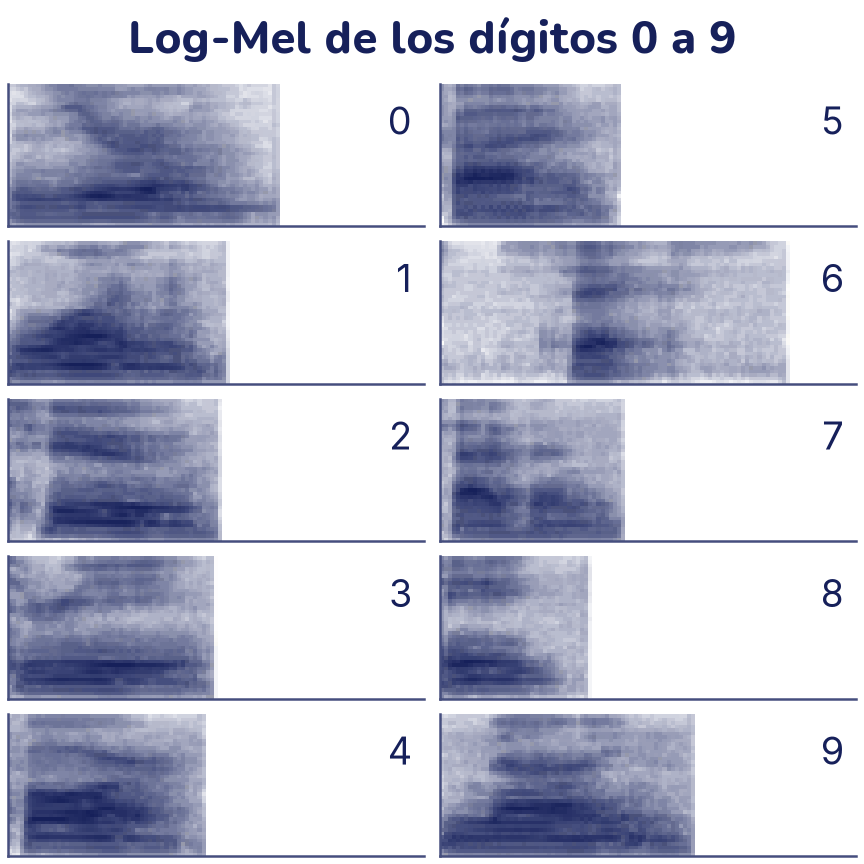

In [ ]:
LARGO = sr_d                               # 1 segundo = 8000 muestras


def a_un_segundo(x):
    """Recorta o rellena con silencio hasta LARGO muestras."""
    if len(x) >= LARGO:
        return x[:LARGO]
    return np.pad(x, (0, LARGO - len(x)))


ondas = torch.from_numpy(np.stack([a_un_segundo(x) for x in audios]))
mel_d = torchaudio.transforms.MelSpectrogram(
    sample_rate=sr_d, n_fft=256, hop_length=80, n_mels=40)
log_mel = torch.log(mel_d(ondas) + 1e-6)   # (audios, bandas, cuadros)
print("Ondas:", tuple(ondas.shape), "  log-Mel:", tuple(log_mel.shape))

# Los diez dígitos dichos por la misma persona
fig, ejes = plt.subplots(5, 2, figsize=(4.8, 4.8))
for d, eje in enumerate(ejes.T.flat):
    k = np.flatnonzero((digitos == d) & (np.array(hablantes) == "jackson")
                       & (tomas == 0))[0]
    eje.imshow(log_mel[k], origin="lower", aspect="auto", cmap=tinta)
    eje.text(0.97, 0.9, str(d), transform=eje.transAxes, ha="right",
             va="top", fontsize=15, fontweight="bold", color="C0")
    eje.set_xticks([])
    eje.set_yticks([])
fig.suptitle("Log-Mel de los dígitos 0 a 9")
plt.show()

*Crédito: espectrogramas hechos con audios del [Free Spoken Digit Dataset](https://github.com/Jakobovski/free-spoken-digit-dataset), de Zohar Jackson y colaboradores, con licencia [CC BY-SA 4.0](https://creativecommons.org/licenses/by-sa/4.0/). La figura se comparte con la misma licencia.*

El dataset está en inglés, porque no hay un conjunto libre igual de ordenado en español; para entender las formas sirve saber cómo suenan: «zero» ≈ «síro», «three» ≈ «zrí», «six» ≈ «sics», «seven» ≈ «séven». Cada dígito tiene su forma. «Six» empieza con una «s», una mancha pareja en todas las bandas antes de la vocal; «seven» tiene dos sílabas, y se ven dos golpes; en «zero» y «three» las bandas se curvan porque la vocal cambia mientras se dice. La parte derecha de cada imagen es el relleno de silencio, y su largo depende de cuánto duró la palabra. Ahora toca que una red aprenda a distinguir esas formas sola.

## Una CNN que escucha

Usamos la división oficial del dataset: las tomas 0 a 4 de cada persona y dígito son la **prueba** (300 audios), que se usa una sola vez al final (tema 7). Del resto separamos las tomas 5 a 9 como **validación** (otros 300), para mirar cómo va el entrenamiento, y las demás son el **entrenamiento** (2400). Las seis personas aparecen en las dos partes, así que medimos si la red reconoce dígitos nuevos **de voces que ya oyó**; reconocer voces nuevas es más difícil. Antes de entrenar, **estandarizamos** con la media y la desviación del entrenamiento, como en el tema 5.

In [ ]:
from torch.utils.data import DataLoader, TensorDataset

es_prueba = torch.from_numpy(tomas < 5)
es_val = torch.from_numpy((tomas >= 5) & (tomas < 10))
es_ent = torch.from_numpy(tomas >= 10)
X = log_mel.unsqueeze(1)                   # un canal: (N, 1, 40, 101)
y = torch.from_numpy(digitos)
media, desvio = X[es_ent].mean(), X[es_ent].std()
X = (X - media) / desvio

cargador_ent = DataLoader(
    TensorDataset(X[es_ent], y[es_ent]), batch_size=64,
    shuffle=True, generator=torch.Generator().manual_seed(0))
cargador_val = DataLoader(TensorDataset(X[es_val], y[es_val]),
                          batch_size=300)
cargador_pru = DataLoader(TensorDataset(X[es_prueba], y[es_prueba]),
                          batch_size=300)
print("Entrenamiento:", len(cargador_ent.dataset),
      "  validación:", len(cargador_val.dataset),
      "  prueba:", len(cargador_pru.dataset))

Entrenamiento: 2400   validación: 300   prueba: 300


La red es la de siempre: bloques de convolución, normalización por lotes (`BatchNorm2d`, la versión para imágenes de la `BatchNorm1d` del tema 19) y ReLU, con max-pooling en medio. Al final, `AdaptiveAvgPool2d((5, 6))` resume cada mapa en una rejilla fija de 5 × 6, sea cual sea el largo del audio, y una capa lineal da los 10 puntajes.

In [ ]:
def bloque(entran, salen):
    """Convolución 3×3 + BatchNorm + ReLU."""
    return nn.Sequential(nn.Conv2d(entran, salen, 3, padding=1),
                         nn.BatchNorm2d(salen), nn.ReLU())


torch.manual_seed(0)
cnn = nn.Sequential(
    bloque(1, 16), nn.MaxPool2d(2),        # (16, 20, 50)
    bloque(16, 32), nn.MaxPool2d(2),       # (32, 10, 25)
    bloque(32, 32),                        # (32, 10, 25)
    nn.AdaptiveAvgPool2d((5, 6)),          # (32, 5, 6)
    nn.Flatten(),                          # 960
    nn.Linear(32 * 5 * 6, 10),
)
print("Parámetros:", sum(p.numel() for p in cnn.parameters()))

Parámetros: 23818


Para entrenar usamos la función `entrenar` del tema 18, tal cual:

In [ ]:
def evaluar(modelo, cargador, funcion_perdida, dispositivo="cpu"):
    """Pérdida media y exactitud de `modelo` sobre `cargador`."""
    modelo.eval()
    suma, aciertos, total = 0.0, 0, 0
    with torch.no_grad():
        for x, y in cargador:
            x, y = x.to(dispositivo), y.to(dispositivo)
            salida = modelo(x)
            suma += funcion_perdida(salida, y).item() * len(y)
            aciertos += (salida.argmax(dim=1) == y).sum().item()
            total += len(y)
    return suma / total, aciertos / total


def entrenar(modelo, cargador_ent, cargador_val, epocas, optimizador,
             funcion_perdida=None, planificador=None, dispositivo="cpu",
             mostrar=True):
    """Entrena `modelo` y devuelve el historial de cada época."""
    if funcion_perdida is None:
        funcion_perdida = nn.CrossEntropyLoss()
    modelo.to(dispositivo)
    historial = {"perdida_ent": [], "exactitud_ent": [],
                 "perdida_val": [], "exactitud_val": []}
    for epoca in range(1, epocas + 1):
        modelo.train()
        suma, aciertos, total = 0.0, 0, 0
        for x, y in cargador_ent:
            x, y = x.to(dispositivo), y.to(dispositivo)
            optimizador.zero_grad()
            salida = modelo(x)
            perdida = funcion_perdida(salida, y)
            perdida.backward()
            optimizador.step()
            suma += perdida.item() * len(y)
            aciertos += (salida.argmax(dim=1) == y).sum().item()
            total += len(y)
        if planificador is not None:
            planificador.step()
        perdida_val, exactitud_val = evaluar(
            modelo, cargador_val, funcion_perdida, dispositivo)
        historial["perdida_ent"].append(suma / total)
        historial["exactitud_ent"].append(aciertos / total)
        historial["perdida_val"].append(perdida_val)
        historial["exactitud_val"].append(exactitud_val)
        if mostrar:
            print(f"Época {epoca}: pérdida {suma / total:.3f}, "
                  f"validación {perdida_val:.3f}, "
                  f"exactitud de validación {exactitud_val:.3f}")
    return historial

In [ ]:
torch.manual_seed(0)
hist = entrenar(cnn, cargador_ent, cargador_val, epocas=8,
                optimizador=torch.optim.Adam(cnn.parameters(), lr=1e-3),
                dispositivo=device)
# La prueba, una sola vez, con la red ya entrenada
_, exactitud_prueba = evaluar(cnn, cargador_pru, nn.CrossEntropyLoss(),
                              device)
print(f"Exactitud de prueba: {exactitud_prueba:.3f}")

Época 1: pérdida 1.888, validación 1.553, exactitud de validación 0.550
Época 2: pérdida 1.063, validación 0.849, exactitud de validación 0.847
Época 3: pérdida 0.601, validación 0.531, exactitud de validación 0.893
Época 4: pérdida 0.368, validación 0.468, exactitud de validación 0.873
Época 5: pérdida 0.257, validación 0.275, exactitud de validación 0.947
Época 6: pérdida 0.193, validación 0.353, exactitud de validación 0.893
Época 7: pérdida 0.150, validación 0.205, exactitud de validación 0.960
Época 8: pérdida 0.116, validación 0.158, exactitud de validación 0.977
Exactitud de prueba: 0.967


La exactitud con los 300 audios de validación sube de 0,550 en la primera época a 0,977 en la octava, con una red de 23 818 parámetros, menos que la CNN de FashionMNIST del tema 20. No sube en línea recta: en la época 4 bajó a 0,873 y en la 6, a 0,893. Con 300 audios, cada uno vale 0,003 de exactitud, y unos pocos audios que cambian de lado mueven el número. Fíjate en lo que pasó: el espectrograma convirtió el problema en uno de imágenes, y la red no «sabe» que está escuchando. Con la red ya entrenada, la medimos una sola vez con la prueba: 0,967, cerca de lo que decía la validación.

## Embeddings de audio con HuBERT

La CNN aprendió desde cero con 2400 ejemplos. La otra forma, como en los temas 22 y 25, es **reutilizar** un modelo que ya aprendió a escuchar con muchísimo audio y usar lo que produce como embedding.

**HuBERT** (de Meta, 2021) es un transformer que se entrenó con 960 horas de audiolibros en inglés **sin ninguna transcripción**: es **autosupervisado**, como BERT en el tema 25. Su truco, en tres pasos:

1. **Cuadros.** Una pila de convoluciones convierte la onda en un vector cada 20 ms. Cada vector es un «cuadro» de audio, el equivalente de un token.
2. **Unidades discretas.** Los cuadros de todo el audio se agrupan con k-means (el tema 14) en unos cientos de grupos. El número de grupo de cada cuadro es una **unidad discreta**: una especie de letra de un alfabeto de sonidos que nadie definió a mano. Así el audio se **tokeniza**.
3. **Tapar y adivinar.** Como BERT tapa palabras, HuBERT tapa tramos de cuadros y aprende a predecir qué unidad había debajo. Para lograrlo tiene que entender el contexto del habla.

El modelo `facebook/hubert-base-ls960` (94 millones de parámetros, licencia Apache-2.0, en [Hugging Face](https://huggingface.co/facebook/hubert-base-ls960)) se baja la primera vez (378 MB). Espera audio a 16 000 Hz, así que primero **remuestreamos** los dígitos de 8000 a 16 000 Hz. Como embedding de cada audio usamos el **promedio** de los vectores de todos sus cuadros, el mismo pooling por promedio del tema 22. Lo hacemos con los 300 audios de prueba, de uno en uno y sin relleno.

In [ ]:
from transformers import AutoFeatureExtractor, AutoModel

extractor = AutoFeatureExtractor.from_pretrained(
    "facebook/hubert-base-ls960")
hubert = AutoModel.from_pretrained("facebook/hubert-base-ls960")
hubert = hubert.to(device).eval()

indices_prueba = np.flatnonzero(tomas < 5)
embeddings = []
with torch.no_grad():
    for k in indices_prueba:
        x16 = torchaudio.functional.resample(
            torch.from_numpy(audios[k]), sr_d, 16000)
        entrada = extractor(x16.numpy(), sampling_rate=16000,
                            return_tensors="pt").to(device)
        cuadros = hubert(**entrada).last_hidden_state  # (1, T, 768)
        embeddings.append(cuadros.mean(dim=1)[0].cpu())
E = torch.stack(embeddings).numpy()
y_h = digitos[indices_prueba]

print(f"Último audio: {len(x16) / 16000:.2f} s ->",
      tuple(cuadros.shape))
print("Embeddings:", E.shape)

Último audio: 0.42 s -> (1, 20, 768)
Embeddings: (300, 768)


El último audio de prueba dura 0,42 s y HuBERT lo convirtió en 20 cuadros, uno cada 20 ms, cada uno de 768 números. El promedio deja un solo vector de 768 por audio, dure lo que dure: otra forma de resolver el problema del largo, sin recortar ni rellenar. Para ver si esos vectores separan los dígitos, los llevamos a 2D con UMAP, como en el tema 22, y probamos un clasificador sencillo encima.

Exactitud por pliegue: [0.78 0.98 0.97 0.92 0.92]
Promedio: 0.913


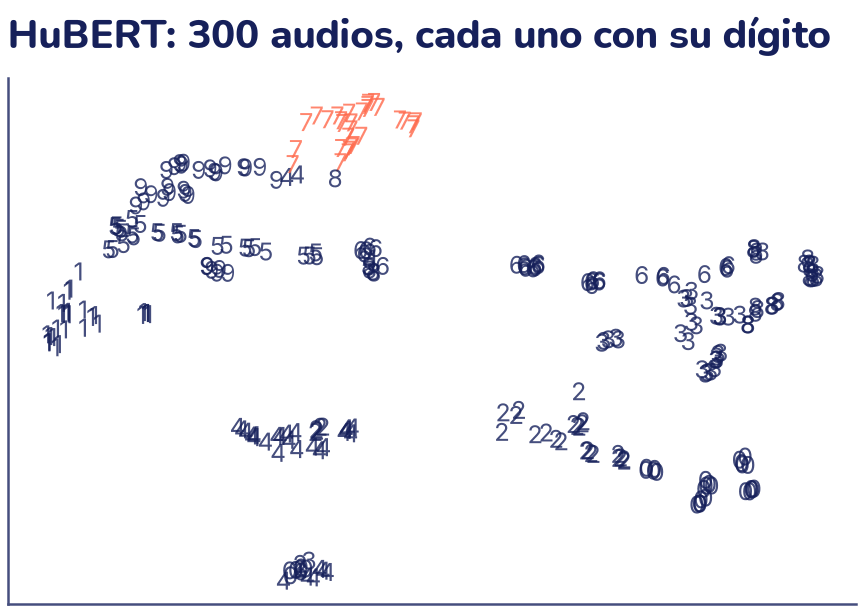

In [ ]:
import umap
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

plano = umap.UMAP(n_neighbors=15, min_dist=0.1, metric="cosine",
                  random_state=0, n_jobs=1).fit_transform(E)

plt.scatter(plano[:, 0], plano[:, 1], s=0)  # solo fija los límites
for (a, b), d in zip(plano, y_h):
    plt.text(a, b, str(d), ha="center", va="center", fontsize=10,
             color="C1" if d == 7 else "C0", alpha=0.8)
plt.title("HuBERT: 300 audios, cada uno con su dígito")
plt.xticks([])
plt.yticks([])
plt.show()

# ¿Alcanza el embedding para clasificar? Validación cruzada, 5 pliegues
clasificador = LogisticRegression(max_iter=2000)
exactitudes = cross_val_score(clasificador, E, y_h, cv=5)
print("Exactitud por pliegue:", np.round(exactitudes, 2))
print(f"Promedio: {exactitudes.mean():.3f}")

*Crédito: figura hecha con audios del [Free Spoken Digit Dataset](https://github.com/Jakobovski/free-spoken-digit-dataset), de Zohar Jackson y colaboradores, con licencia [CC BY-SA 4.0](https://creativecommons.org/licenses/by-sa/4.0/). La figura se comparte con la misma licencia.*

UMAP no sabe nada de dígitos, y HuBERT nunca los aprendió con etiquetas. Aun así, los audios del mismo dígito tienden a juntarse: el 7 (en coral) forma su propio grupo, igual que el 1 y el 0. Hay mezclas, como el 3 con el 8, y dígitos partidos en dos grupos, como el 4 y el 6, quizás por voces distintas.

Una regresión logística sobre estos embeddings, con validación cruzada de 5 pliegues, acierta en promedio 0,913, sin entrenar ni una convolución y con solo 240 audios para entrenar en cada pliegue. La exactitud cambia mucho entre pliegues. Como los audios están ordenados por dígito y por persona, el primer pliegue se prueba casi solo con los audios de *george*, y ninguno de sus audios queda para entrenar en ese pliegue: ante esa voz nueva, acierta 0,78. La CNN llegó más alto, pero entrenó con 2400 audios de las mismas seis voces de la prueba.

## Transcribir con Whisper

Reconocer diez palabras sueltas es una cosa; escribir lo que alguien lee durante un minuto, otra. **Whisper** (de OpenAI, 2022, licencia Apache-2.0) es un transformer **codificador-decodificador**, como el traductor del tema 25:

- el **codificador** recibe un log-Mel de 80 bandas de hasta 30 segundos (3000 cuadros de 10 ms) y lo convierte en vectores;
- el **decodificador** escribe el texto token por token, mirando esos vectores con atención cruzada, igual que un modelo de lenguaje que escribe «escuchando».

Se entrenó con unas 680 000 horas de audio de internet con su transcripción, en casi cien idiomas (dos tercios en inglés), y por eso funciona en español sin ajustarlo. Hay varios tamaños; usaremos los dos más chicos, que corren bien en una CPU: [`whisper-tiny`](https://huggingface.co/openai/whisper-tiny) (38 millones de parámetros, 151 MB) y [`whisper-base`](https://huggingface.co/openai/whisper-base) (73 millones, 290 MB).

In [ ]:
from transformers import AutoModelForSpeechSeq2Seq, AutoProcessor

whisper = {}
for nombre in ["tiny", "base"]:
    ruta = f"openai/whisper-{nombre}"
    procesador = AutoProcessor.from_pretrained(ruta)
    modelo = AutoModelForSpeechSeq2Seq.from_pretrained(ruta)
    whisper[nombre] = (procesador, modelo.to(device).eval())
    millones = sum(p.numel() for p in modelo.parameters()) / 1e6
    print(f"whisper-{nombre}: {millones:.0f} millones de parámetros")


@torch.no_grad()
def transcribir(audio, nombre, idioma):
    """Texto de un audio a 16 000 Hz, con el Whisper `nombre`."""
    procesador, modelo = whisper[nombre]
    largo = len(audio) > 30 * 16000
    if largo:
        # Más de 30 s: Whisper lo procesa en tramos de 30 s
        x = procesador(audio, sampling_rate=16000, return_tensors="pt",
                       truncation=False, padding="longest",
                       return_attention_mask=True)
    else:
        x = procesador(audio, sampling_rate=16000, return_tensors="pt")
    ids = modelo.generate(**x.to(device), language=idioma,
                          task="transcribe", return_timestamps=largo)
    return procesador.batch_decode(ids, skip_special_tokens=True)[0]


def mostrar(texto):
    """Imprime el texto en renglones de 72 caracteres."""
    print(textwrap.fill(texto.strip(), 72))


texto_tiny = transcribir(onda, "tiny", "es")
mostrar(texto_tiny)

whisper-tiny: 38 millones de parámetros
whisper-base: 73 millones de parámetros
En el lugar de la mancha, de cuyo nombre no quiero acordarme. No mucho
tiempo que vivía, ni algo de los delanza en a estiguero, a darga
antiguo, rocin flaco y galgo corredor. Una olla de algo más paca que
carnero, salpicón por las noches, duelo si que brantos los sábados,
lentejas los viernes, algún paromino de añadiduría los domingos,
consumían las tres partes de su haciendo. El resto de ella concluyan
sallo de Velarte, calzas debyudo para las fiestas con sus pantunflos de
lo mismo, y los días de entresemana, se onraba con su bello ríde lo más
fino. Tenían su casa a un amac que pasaba de los cuarenta y una sobrina
que no llegaba los 20. Y un monso de campo y plaza que asciencia ya va
el rocin, como tomaba la poda de raro.


El procesador hace el log-Mel; `generate` hace la decodificación codiciosa del tema 24, token por token, así que el resultado sale igual cada vez. Fijamos `language="es"`: si no, Whisper adivina el idioma con los primeros segundos. Con más de 30 segundos hay que pedirle que marque tiempos (`return_timestamps=True`) para que avance de tramo en tramo; en los ejercicios vas a ver qué pasa si no. `transformers` también tiene una forma más corta, `pipeline("automatic-speech-recognition", model="openai/whisper-tiny")`, que da el mismo texto.

Para un modelo de 38 millones de parámetros que nunca oyó este audio, no está mal: se entiende casi todo. Pero hay errores de varios tipos:

- palabras que suenan parecido: «paca» por «vaca», «haciendo» por «hacienda», «monso» por «mozo»;
- palabras partidas o pegadas: «a darga» por «adarga», «delanza» por «de lanza»;
- palabras que no existen: «estiguero», «amac»;
- y cosas que no son errores de oído: Whisper escribió «lentejas» y «de ella», en el español de hoy, donde Cervantes escribió «lantejas» y «della», y «20» en cifras.

### Medir los errores: la tasa de error de palabras

Para comparar modelos hace falta un número. La **tasa de error de palabras** (WER, de *word error rate*) alinea la transcripción con la **referencia** (lo que de verdad se dijo) y cuenta tres tipos de error: palabras **sustituidas** (S), **borradas** (B) e **insertadas** (I). Después divide entre *N*, la cantidad de palabras de la referencia:

$$\text{WER} = \frac{S + B + I}{N}$$

Un WER de 0 es perfecto; 0,25 es una palabra mala de cada cuatro. Puede pasar de 1 si el modelo inventa muchas palabras de más. La alineación es la que da menos errores, y la calcula `jiwer`. Antes de medir, pasamos los dos textos a minúsculas y les quitamos la puntuación: no queremos contar como error una coma o una mayúscula.

In [ ]:
import jiwer

REFERENCIA = (
    "En un lugar de la Mancha, de cuyo nombre no quiero acordarme, no ha "
    "mucho tiempo que vivía un hidalgo de los de lanza en astillero, "
    "adarga antigua, rocín flaco y galgo corredor. Una olla de algo más "
    "vaca que carnero, salpicón las más noches, duelos y quebrantos los "
    "sábados, lantejas los viernes, algún palomino de añadidura los "
    "domingos, consumían las tres partes de su hacienda. El resto della "
    "concluían sayo de velarte, calzas de velludo para las fiestas, con "
    "sus pantuflos de lo mesmo, y los días de entresemana se honraba con "
    "su vellorí de lo más fino. Tenía en su casa una ama que pasaba de "
    "los cuarenta, y una sobrina que no llegaba a los veinte, y un mozo "
    "de campo y plaza, que así ensillaba el rocín como tomaba la "
    "podadera.")


def normalizar(texto):
    """Minúsculas, sin puntuación y con un espacio entre palabras."""
    texto = re.sub(r"[^\w\s]", " ", texto.lower())
    return " ".join(texto.split())


ref = normalizar(REFERENCIA)
hip = normalizar(texto_tiny)
cuentas = jiwer.process_words(ref, hip)
print("Palabras de la referencia:", len(ref.split()))
print("Sustituidas:", cuentas.substitutions,
      "  borradas:", cuentas.deletions,
      "  insertadas:", cuentas.insertions)
print(f"WER: {cuentas.wer:.3f}")

Palabras de la referencia: 135
Sustituidas: 38   borradas: 4   insertadas: 7
WER: 0.363


De las 135 palabras de la referencia, 38 salieron cambiadas, faltan 4 y sobran 7: (38 + 4 + 7) / 135 = 49 / 135 ≈ 0,363. Más o menos una palabra de cada tres está mal. Una palabra partida cuenta doble: «adarga» → «a darga» es una sustitución más una inserción.

### ¿Y con ruido? ¿Y en inglés?

Una grabación de verdad casi nunca es limpia. Para medir cuánto le afecta el ruido, le sumamos ruido aleatorio con una **relación señal-ruido** (SNR) de 10 decibeles: la voz tiene 10 veces más potencia que el ruido (10 dB es un factor 10 en potencia, como viste en el espectrograma), como hablar con un ventilador fuerte al lado. Y para comparar idiomas, medimos también con 10 frases en inglés de **LibriSpeech** (otro conjunto de audiolibros de LibriVox, de Panayotov y colaboradores, 2015, con licencia [CC BY 4.0](https://www.openslr.org/12)), tomadas de un recorte pequeño publicado en [Hugging Face](https://huggingface.co/datasets/hf-internal-testing/librispeech_asr_dummy).

Frases en inglés: 10  duración total: 110 s
Ejemplo: mister quilter is the apostle of the middle classes and we are
glad to welcome his gospel
modelo           es  es + ruido          en  en + ruido
tiny          0.363       0.452       0.116       0.208
base          0.281       0.341       0.093       0.208


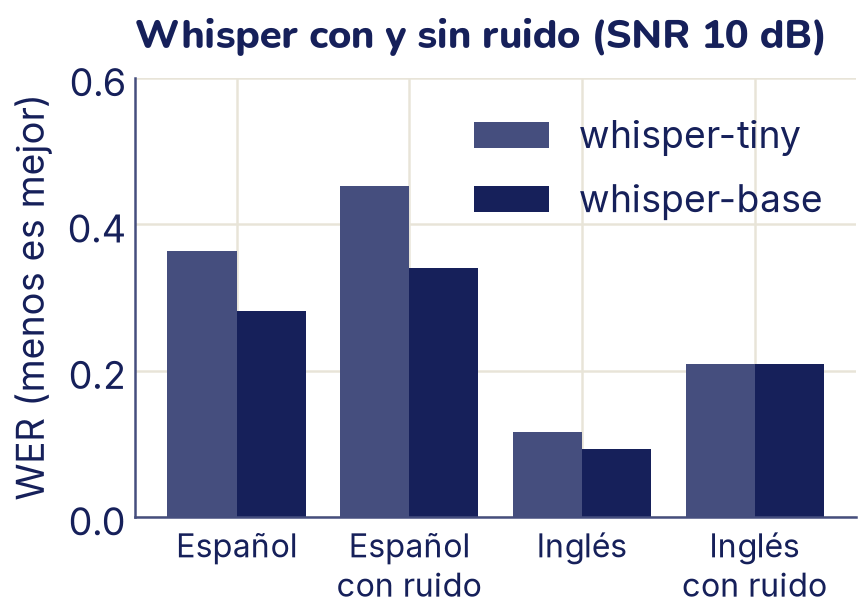

In [ ]:
import io

import pandas as pd
from huggingface_hub import hf_hub_download


def con_ruido(audio, snr_db, semilla=0):
    """Suma ruido gaussiano con la relación señal-ruido pedida."""
    rng = np.random.default_rng(semilla)
    potencia_ruido = np.mean(audio ** 2) / 10 ** (snr_db / 10)
    ruido = rng.normal(0, np.sqrt(potencia_ruido), len(audio))
    return (audio + ruido).astype(np.float32)


# 10 frases de LibriSpeech (Panayotov et al., 2015), licencia CC BY 4.0
parquet = hf_hub_download("hf-internal-testing/librispeech_asr_dummy",
                          "clean/validation-00000-of-00001.parquet",
                          repo_type="dataset")
frases = pd.read_parquet(parquet).head(10)
ingles = [sf.read(io.BytesIO(a["bytes"]), dtype="float32")[0]
          for a in frases["audio"]]
refs_en = [normalizar(texto) for texto in frases["text"]]
print("Frases en inglés:", len(ingles), " duración total:",
      f"{sum(len(x) for x in ingles) / 16000:.0f} s")
mostrar("Ejemplo: " + refs_en[0])

textos, wer = {}, {}
for nombre in ["tiny", "base"]:
    textos[nombre, "es"] = transcribir(onda, nombre, "es")
    textos[nombre, "es + ruido"] = transcribir(con_ruido(onda, 10),
                                               nombre, "es")
    textos[nombre, "en"] = [transcribir(x, nombre, "en")
                            for x in ingles]
    textos[nombre, "en + ruido"] = [
        transcribir(con_ruido(x, 10, semilla=i), nombre, "en")
        for i, x in enumerate(ingles)]
    for caso in ["es", "es + ruido"]:
        wer[nombre, caso] = jiwer.wer(ref, normalizar(textos[nombre, caso]))
    for caso in ["en", "en + ruido"]:
        hips = [normalizar(t) for t in textos[nombre, caso]]
        wer[nombre, caso] = jiwer.wer(refs_en, hips)

casos = ["es", "es + ruido", "en", "en + ruido"]
print("modelo " + "".join(f"{c:>12}" for c in casos))
for nombre in ["tiny", "base"]:
    print(f"{nombre:6} " + "".join(f"{wer[nombre, c]:12.3f}"
                                  for c in casos))

posiciones = np.arange(len(casos))
for desplazar, nombre, color in [(-0.2, "tiny", "C2"),
                                 (0.2, "base", "C0")]:
    plt.bar(posiciones + desplazar, [wer[nombre, c] for c in casos],
            width=0.4, color=color, label=f"whisper-{nombre}")
plt.xticks(posiciones, ["Español", "Español\ncon ruido", "Inglés",
                        "Inglés\ncon ruido"], fontsize=13)
plt.ylabel("WER (menos es mejor)")
plt.title("Whisper con y sin ruido (SNR 10 dB)")
# Espacio arriba para que la leyenda no tape las barras
plt.ylim(0, 0.6)
plt.legend(loc="upper right")
plt.show()

Tres cosas para leer en la tabla:

- **El modelo más grande se equivoca menos.** Con casi el doble de parámetros, base baja el WER en español de 0,363 a 0,281. Solo empatan en inglés con ruido (0,208).
- **El ruido empeora a los dos en todos los casos.** En español, tiny pasa de 0,363 a 0,452; en inglés, base pasa de 0,093 a 0,208.
- **Sin ruido, en inglés el WER es unas tres veces menor.** Una parte es el idioma: cerca de dos tercios de los datos de entrenamiento de Whisper son en inglés. Otra parte son los audios: el castellano de hace 400 años, con palabras como «astillero» o «vellorí», es más difícil que frases de novelas en inglés moderno.

Con un solo audio en español y 10 frases en inglés, estas diferencias son una pista, no una conclusión: para comparar modelos en serio hacen falta muchos más audios, de muchas voces.

## Modelos de audio y lenguaje

Whisper hace una sola cosa: escribir lo que oye. En los últimos años aparecieron modelos que **escuchan y conversan**: unen un codificador de audio (muchas veces derivado del de Whisper) con un LLM como el del tema 24, de modo que el LLM recibe «tokens de audio» además de tokens de texto. Dos ejemplos:

- **Qwen-Audio** y **Qwen2-Audio**, de Alibaba Cloud, con unos 8000 millones de parámetros.
- **Voxtral**, de Mistral AI (2025), en dos tamaños: Mini, con unos 3000 millones, y Small, con unos 24 000 millones.

A esos modelos se les puede dar un audio y una instrucción: «¿de qué habla esta grabación?», «¿la persona suena enojada?», «resume la reunión», «¿qué instrumento suena?». No los vamos a correr: tienen miles de millones de parámetros y necesitan una GPU con mucha memoria. Para elegir:

- Si solo necesitas **el texto** de lo que se dijo, un modelo de transcripción como Whisper es más chico, más rápido y más fácil de medir con el WER.
- Si necesitas **entender** el audio más allá de las palabras (el tono, los sonidos que no son habla) o responder preguntas sobre él, conviene un modelo de audio y lenguaje.
- Una tercera vía, la del mini-proyecto: transcribir con Whisper y pasarle el texto a un LLM. Funciona bien cuando lo importante son las palabras, y cada pieza se puede medir por separado.

## Lo que aprendiste y lo que sigue

- Un audio digital es un vector de **muestras**. La **frecuencia de muestreo** dice cuántas hay por segundo, y solo se pueden representar frecuencias de hasta su mitad (**Nyquist**); más arriba aparece el *aliasing*.
- La **FFT** descompone una señal en frecuencias. La **STFT** la aplica por ventanas y da el **espectrograma**: tiempo, frecuencia e intensidad. La ventana larga separa frecuencias cercanas y la corta ubica bien los instantes: no se pueden tener las dos.
- La **escala de Mel** imita al oído; el **log-Mel** es la «imagen» que usan casi todos los modelos de audio, Whisper incluido.
- Con audios recortados o rellenados a un largo fijo, una **CNN** pequeña sobre log-Mel clasifica dígitos hablados; los **embeddings de HuBERT**, un modelo autosupervisado que tokeniza el audio en unidades discretas, separan los dígitos sin haberlos visto nunca.
- **Whisper** transcribe con un codificador-decodificador sobre log-Mel. El **WER** mide sus errores; depende del tamaño del modelo, del ruido, del idioma y de cómo normalices los textos.

En el tema 29 vas a dar vuelta la flecha: en lugar de convertir datos en números para reconocerlos, vas a entrenar modelos que **generan** datos nuevos.

# Ejercicios

## Antes de empezar

Varios ejercicios usan lo que construiste en la teoría: `onda` y `sr` (el *Quijote*), `stft`, `en_db`, `tinta`, `audios`, `digitos`, `tomas`, `a_un_segundo`, `mel_d`, `media`, `desvio`, `cnn`, `bloque`, `entrenar`, `evaluar`, `cargador_val`, `whisper`, `transcribir`, `mostrar`, `REFERENCIA`, `normalizar`, `ref`, `con_ruido`, `textos` y `wer`. En este cuaderno, ejecuta las celdas de la teoría y trabaja en los ejercicios, que vienen debajo. La primera vez baja los audios y los modelos. Intenta cada ejercicio antes de abrir la respuesta.

## Ejercicios

### 1. ¿Qué sonido es cada uno?

Estos son los espectrogramas de cinco sonidos sintéticos de un segundo, en desorden: un **tono grave** de 200 Hz, un **tono agudo** de 1500 Hz, un **silbido que sube** de 200 a 2000 Hz, **ruido** (como un «shhh») y una **nota con armónicos** (300 Hz más sus múltiplos 600, 900 y 1200 Hz, cada uno más suave). Di cuál es cuál y explica qué te delató en cada caso.

In [ ]:
# @title El código que hizo la figura (trae la respuesta: ábrelo al final): código (doble clic para verlo)
sr_e = 8000
t_e = np.arange(sr_e) / sr_e
rng = np.random.default_rng(1)
sonidos = {
    "tono grave": np.sin(2 * np.pi * 200 * t_e),
    "tono agudo": np.sin(2 * np.pi * 1500 * t_e),
    # La frecuencia sube de 200 a 2000 Hz en un segundo
    "silbido que sube": np.sin(2 * np.pi * (200 * t_e + 900 * t_e ** 2)),
    "ruido": 0.5 * rng.normal(size=sr_e),
    "nota con armónicos": sum(np.sin(2 * np.pi * 300 * k * t_e) / k
                              for k in [1, 2, 3, 4]),
}
orden = ["ruido", "tono grave", "nota con armónicos", "tono agudo",
         "silbido que sube"]

fig, ejes = plt.subplots(3, 2, figsize=(4.8, 4.8))
for eje, letra, nombre in zip(ejes.flat, "ABCDE", orden):
    S = en_db(stft(sonidos[nombre], 256, 64))
    eje.imshow(S, origin="lower", aspect="auto", cmap=tinta,
               vmin=S.max() - 60, extent=[0, 1, 0, sr_e / 2])
    eje.set_ylim(0, 2500)
    eje.set_title(letra)
    eje.set_xticks([])
    eje.set_yticks([0, 1000, 2000])
    eje.grid(False)
ejes[2, 1].axis("off")
plt.show()

for letra, nombre in zip("ABCDE", orden):
    print(letra, "=", nombre)

<details>
<summary>Respuesta</summary>

- **A, ruido:** tinta repartida en todas las frecuencias y todo el tiempo, sin rayas. El ruido no tiene tono: tiene un poco de cada frecuencia.
- **B, tono grave:** una sola raya horizontal, abajo, en 200 Hz.
- **C, nota con armónicos:** una escalera de cuatro rayas paralelas igual de separadas (300, 600, 900 y 1200 Hz). Así se ven las vocales de la voz. Los armónicos más altos suenan más suave, pero el espectrograma está en decibeles, una escala logarítmica, y por eso las cuatro rayas se ven casi igual de oscuras.
- **D, tono agudo:** una sola raya, más arriba, en 1500 Hz.
- **E, silbido que sube:** una raya inclinada: la frecuencia cambia con el tiempo. La frecuencia es la velocidad con que avanza lo que está dentro del seno (dividido entre 2π): si eso crece como 200*t* + 900*t*², su velocidad (su derivada, tema 5) es 200 + 1800*t*, que sube en línea recta de 200 a 2000 Hz.

</details>

### 2. Cuentas de muestras, ventanas y cuadros

Sin computadora:

1. Los audios de FSDD tienen 8000 muestras por segundo. ¿Cuál es la frecuencia más alta que pueden representar?
2. El log-Mel de FSDD usa `n_fft=256` y `hop_length=80`. ¿Cuántos milisegundos dura cada ventana? ¿Cada cuánto empieza una? ¿Cuántos cuadros salen de un audio de 1 s, si `torchaudio` agrega un cuadro más por el borde?
3. Whisper usa 16 000 muestras por segundo y un salto de 160. ¿Cuántos cuadros tiene su entrada de 30 segundos? ¿Y el *Quijote*, de 876 800 muestras?

Después comprueba con código, y mira qué pasa si le das a Whisper más de 30 segundos sin pedirle los tiempos.

<details>
<summary>Respuesta</summary>

1. La frecuencia de Nyquist: 8000 / 2 = **4000 Hz**. Por eso el espectrograma de Mel de FSDD llega solo hasta ahí.
2. La ventana dura 256 / 8000 = 0,032 s = **32 ms**, y empieza una cada 80 / 8000 = 0,01 s = **10 ms**. En 1 s caben 8000 / 80 = 100 saltos, más el cuadro del borde: **101 cuadros**.
3. 30 s son 480 000 muestras; entre 160, **3000 cuadros**. El *Quijote*: 876 800 / 160 = **5480 cuadros** (el procesador de Whisper no agrega el cuadro del borde): más de los 3000 que Whisper mira de una vez.

</details>

In [ ]:
# @title Respuesta: código (doble clic para verlo)
print("Nyquist de FSDD:", sr_d // 2, "Hz")
print("Ventana:", 1000 * 256 / sr_d, "ms   salto:", 1000 * 80 / sr_d,
      "ms   cuadros en 1 s:", log_mel.shape[-1])

procesador, modelo = whisper["tiny"]
x = procesador(onda, sampling_rate=16000, return_tensors="pt",
               truncation=False, padding="longest",
               return_attention_mask=True)
print("Cuadros del Quijote:", x["input_features"].shape[-1])
modelo.generate(**x, language="es")

<details>
<summary>Respuesta (sigue)</summary>

Whisper se entrenó con tramos de 30 segundos, 3000 cuadros, y no acepta una entrada más larga de una vez. Con `return_timestamps=True` (lo que hace `transcribir`) el modelo marca dónde termina cada frase y avanza de tramo en tramo: así transcribe audios de cualquier largo.

</details>

### 3. Normalizar antes de medir

El WER de la teoría se calculó después de pasar los textos a minúsculas y quitar la puntuación. Calcula el WER de `whisper-base` con el *Quijote* de tres formas: con los textos tal cual, normalizados como en la teoría, y además corrigiendo dos diferencias que no son errores de oído: los números escritos con cifras y el castellano antiguo (*lantejas*, *della* y *mesmo* se dicen hoy *lentejas*, *de ella* y *mismo*). ¿Cuál de los tres números es el «verdadero»?

In [ ]:
# @title Respuesta: código (doble clic para verlo)
import jiwer

hip_base = textos["base", "es"]
print(f"Tal cual:     {jiwer.wer(REFERENCIA, hip_base):.3f}")
print(f"Normalizado:  {jiwer.wer(ref, normalizar(hip_base)):.3f}")

# Lo que no son errores de oído: cifras y castellano antiguo
cambios = {"40": "cuarenta", "20": "veinte", "lantejas": "lentejas",
           "della": "de ella", "mesmo": "mismo"}


def modernizar(texto):
    """Cambia palabra por palabra según el diccionario `cambios`."""
    return " ".join(cambios.get(p, p) for p in texto.split())


print(f"Además, sin cifras ni arcaísmos: "
      f"{jiwer.wer(modernizar(ref), modernizar(normalizar(hip_base))):.3f}")

<details>
<summary>Respuesta</summary>

El mismo audio y la misma transcripción dan tres WER distintos:

- **Tal cual, 0,311.** Cuenta como error «Mancha,» frente a «mancha»: una coma y una mayúscula no son errores de oído.
- **Normalizado, 0,281.** Es el de la teoría, la forma habitual de medir.
- **Sin cifras ni arcaísmos, 0,235.** Whisper oyó bien «cuarenta», «veinte», «lantejas», «della» y «mesmo», pero los escribió como se escriben hoy («40», «20», «lentejas», «de ella», «mismo»). Ojo: «della» pasa a ser dos palabras, así que la referencia también cambia de largo.

Ninguno es «el verdadero»: depende de qué quieres medir. Si te importa entender lo que se dijo, el tercero es más justo; si necesitas el texto exacto de Cervantes, el segundo. Lo que sí importa es **decir siempre cómo normalizaste** y comparar modelos solo con la misma normalización. Fíjate que lo que queda (0,235) son errores de verdad: «haciendo», «salio», «pantunflos».

</details>

### 4. Whisper tiny frente a base: tiempo y errores

Mide cuánto tarda cada modelo en transcribir el *Quijote* con `time.perf_counter` y ponlo al lado de su WER (sin ruido y con ruido, del diccionario `wer` de la teoría) y de su tamaño. ¿Cuándo elegirías el chico?

In [ ]:
# @title Respuesta: código (doble clic para verlo)
import time

tiempos = {}
for nombre in ["tiny", "base"]:
    inicio = time.perf_counter()
    transcribir(onda, nombre, "es")
    tiempos[nombre] = time.perf_counter() - inicio
    millones = sum(p.numel() for p in whisper[nombre][1].parameters())
    print(f"{nombre}: {millones / 1e6:.0f} M de parámetros, "
          f"WER {wer[nombre, 'es']:.3f} sin ruido y "
          f"{wer[nombre, 'es + ruido']:.3f} con ruido")
print("¿base tardó más que tiny?", tiempos["base"] > tiempos["tiny"])

<details>
<summary>Respuesta</summary>

Los segundos exactos dependen de tu computadora, por eso el código solo imprime cuál tardó más; imprime `tiempos` para ver los tuyos. Base tiene casi el doble de parámetros y tarda más, pero se equivoca menos: el WER baja de 0,363 a 0,281 sin ruido y de 0,452 a 0,341 con ruido. Tiny conviene cuando la velocidad o la memoria mandan (un celular, subtítulos en vivo, miles de horas de audio que procesar) y se puede tolerar una palabra mala de cada tres; base, o uno más grande, cuando el texto tiene que salir bien. Los dos son chicos: Whisper tiene tamaños de hasta unos 1500 millones de parámetros, mucho mejores pero que piden una GPU.

</details>

### 5. Aumentación: ruido y desplazamiento

1. Evalúa la `cnn` de la teoría con los 300 audios de validación **con ruido** (SNR 10 dB). Usamos la validación y no la prueba porque vamos a comparar dos redes. ¿Cuánto baja la exactitud?
2. Entrena una CNN igual con **aumentación**: en cada época, cada audio de entrenamiento se corre en el tiempo hasta 0,1 s y, la mitad de las veces, al azar, se le suma ruido con una SNR al azar entre 5 y 20 dB. Compara las dos redes con y sin ruido.

In [ ]:
# @title Respuesta: código (doble clic para verlo)
from torch.utils.data import DataLoader, Dataset


def preparar(ondas_1s):
    """De ondas de 1 s a log-Mel estandarizado con un canal."""
    return ((torch.log(mel_d(ondas_1s) + 1e-6) - media) / desvio
            ).unsqueeze(-3)


validacion = np.flatnonzero((tomas >= 5) & (tomas < 10))
y_validacion = torch.from_numpy(digitos[validacion])
ruidosas = torch.from_numpy(np.stack(
    [a_un_segundo(con_ruido(audios[k], 10, semilla=int(k)))
     for k in validacion]))
cargador_ruido = DataLoader(
    torch.utils.data.TensorDataset(preparar(ruidosas), y_validacion),
    batch_size=300)
perdida = nn.CrossEntropyLoss()
print(f"CNN sin aumentación: limpio "
      f"{evaluar(cnn, cargador_val, perdida, device)[1]:.3f}, "
      f"con ruido {evaluar(cnn, cargador_ruido, perdida, device)[1]:.3f}")


class DigitosAumentados(Dataset):
    """Cada vez que se pide un audio, sale con otro ruido y corrimiento."""

    def __init__(self, indices):
        self.ondas = torch.from_numpy(
            np.stack([a_un_segundo(audios[k]) for k in indices]))
        self.y = torch.from_numpy(digitos[indices])

    def __len__(self):
        return len(self.y)

    def __getitem__(self, i):
        x = self.ondas[i]
        # Correr hasta 800 muestras (0,1 s) a la derecha. roll es
        # circular: lo que sale por el final entra por el principio; como
        # el final es silencio de relleno, lo que vuelve es silencio
        x = torch.roll(x, int(torch.randint(0, 800, (1,))))
        # La mitad de las veces, ruido con una SNR entre 5 y 20 dB
        if torch.rand(1) < 0.5:
            snr = 5 + 15 * torch.rand(1)
            potencia = x.pow(2).mean() / 10 ** (snr / 10)
            x = x + torch.randn(len(x)) * potencia.sqrt()
        return preparar(x), self.y[i]


cargador_aum = DataLoader(
    DigitosAumentados(np.flatnonzero(tomas >= 10)), batch_size=64,
    shuffle=True, generator=torch.Generator().manual_seed(0))
torch.manual_seed(0)
cnn_aum = nn.Sequential(
    bloque(1, 16), nn.MaxPool2d(2), bloque(16, 32), nn.MaxPool2d(2),
    bloque(32, 32), nn.AdaptiveAvgPool2d((5, 6)), nn.Flatten(),
    nn.Linear(32 * 5 * 6, 10))
entrenar(cnn_aum, cargador_aum, cargador_val, epocas=8,
         optimizador=torch.optim.Adam(cnn_aum.parameters(), lr=1e-3),
         dispositivo=device, mostrar=False)
print(f"CNN con aumentación: limpio "
      f"{evaluar(cnn_aum, cargador_val, perdida, device)[1]:.3f}, "
      f"con ruido "
      f"{evaluar(cnn_aum, cargador_ruido, perdida, device)[1]:.3f}")

<details>
<summary>Respuesta</summary>

- **Sin aumentación**, el ruido hunde a la red de 0,977 a 0,497: nunca oyó ruido, y con él los silencios entre sonidos del log-Mel se llenan de tinta.
- **Con aumentación**, la red pierde un poco con los audios limpios (0,967 frente a 0,977) pero aguanta mucho mejor el ruido (0,820). Aprendió que el ruido y la posición exacta de la palabra no importan para decidir el dígito.

Es el mismo truco del tema 20 (voltear y recortar fotos), adaptado al audio: el ruido y el corrimiento producen audios nuevos y creíbles sin grabar nada. Fíjate en dos detalles del código. La aumentación cambia en cada época, porque se aplica en `__getitem__`, cada vez que se pide un audio. Y el ruido se suma **a la onda**, antes del log-Mel, como pasaría con un micrófono de verdad.

</details>

### 6. ¿Qué modelo usarías?

Para cada caso, elige entre **Whisper solo**, **Whisper y después un LLM de texto** o **un modelo de audio y lenguaje** (como Qwen2-Audio o Voxtral), y explica por qué:

1. Subtitular los videos de un canal de cocina.
2. Saber si en una llamada a un servicio de atención el cliente suena molesto.
3. Hacer un resumen con las tareas acordadas en una reunión grabada, en una computadora sin GPU.
4. Detectar si en una grabación de la calle se oye una sirena.
5. Un celular que tiene que escribir lo que dices mientras hablas, sin internet.

<details>
<summary>Respuesta</summary>

1. **Whisper solo.** Se necesitan las palabras y sus tiempos, y nada más; además, el WER permite medir qué tan buenos son los subtítulos.
2. **Un modelo de audio y lenguaje.** El enojo está en el tono, el volumen y el ritmo, no solo en las palabras; una transcripción lo pierde.
3. **Whisper y después un LLM de texto.** Lo importante son las palabras, y las dos piezas son chicas: es justo el mini-proyecto. Además, cada parte se mide por separado.
4. **Un modelo de audio y lenguaje** (o un clasificador de sonidos entrenado para eso, como la CNN de dígitos). Una sirena no es habla: Whisper no la escribiría.
5. **Whisper solo, y del tamaño más chico** (tiny), o un modelo de transcripción pensado para el celular. Tiene que ir rápido y caber en el teléfono; un modelo de miles de millones de parámetros no entra.

</details>

## Mini-proyecto: transcribir y resumir

Vas a armar una cadena de dos modelos: **Whisper** escribe lo que se dice en un audio en español y **Qwen2.5-0.5B-Instruct**, el LLM del tema 24, lo resume. Y vas a **medir los errores de cada paso**.

**El audio.** Graba unos dos minutos en español: tú contando algo (tu colegio, una receta, un partido) o, con su permiso, alguien de tu familia. Escribe a mano lo que se dice: esa es tu **referencia**. Si prefieres no grabarte, usa el *Quijote* de la teoría, con `REFERENCIA`; así están hechos los resultados de abajo. Lee tu audio con `sf.read` y, si no está a 16 000 Hz o tiene dos canales, conviértelo con `onda.mean(axis=1)` y `torchaudio.functional.resample`. Los celulares graban en .m4a, .aac u .opus (WhatsApp), y `soundfile` no lee esos formatos: conviértelo antes en una celda de Colab con `!ffmpeg -i mi_audio.m4a -ar 16000 -ac 1 mi_audio.wav`, que de paso lo deja a 16 000 Hz y en un solo canal.

**Pasos.**

1. **Transcribe** con `whisper-tiny` y con `whisper-base` y mide el WER de cada uno contra tu referencia, normalizando los dos textos.
2. **Resume** con Qwen, de forma determinista (`do_sample=False`), con una instrucción clara: «Resume en dos oraciones…». Haz tres resúmenes: de la referencia, de la transcripción de base y de la de tiny.
3. **Mide el resumen.** Antes de leer los resúmenes, anota cinco a ocho **datos clave** del audio (quién, qué, dónde, cuántos). Para cada resumen, cuenta cuántos datos clave aparecen y si hay algo **inventado** que no está en el audio.
4. **Concluye.** ¿Los errores de Whisper llegan al resumen? ¿El resumen de la referencia es perfecto, o Qwen también se equivoca? ¿Dónde está el eslabón más débil de la cadena?

In [ ]:
# @title Resultados de referencia con el *Quijote*, para comprobar los tuyos: código (doble clic para verlo)
from transformers import AutoModelForCausalLM, AutoTokenizer

nombre = "Qwen/Qwen2.5-0.5B-Instruct"
tok = AutoTokenizer.from_pretrained(nombre)
llm = AutoModelForCausalLM.from_pretrained(nombre, dtype=torch.float32)
llm = llm.to(device).eval()


@torch.no_grad()
def resumir(texto, max_tokens=150):
    """Resumen determinista de `texto` con Qwen."""
    mensajes = [
        {"role": "system",
         "content": "Resumes textos en español. Usa solo datos del texto."},
        {"role": "user",
         "content": "Resume en dos oraciones este texto:\n\n" + texto},
    ]
    x = tok.apply_chat_template(mensajes, add_generation_prompt=True,
                                return_tensors="pt", return_dict=True)
    x = x.to(device)
    salida = llm.generate(**x, max_new_tokens=max_tokens,
                          do_sample=False)
    return tok.decode(salida[0, x["input_ids"].shape[1]:],
                      skip_special_tokens=True)


# Paso 1: WER de cada transcripción (ya calculado en la teoría)
for modelo_w in ["tiny", "base"]:
    print(f"WER de whisper-{modelo_w}: {wer[modelo_w, 'es']:.3f}")

# Pasos 2 y 3: resumir y buscar los datos clave
datos_clave = {
    "hidalgo": ["hidalgo"], "la Mancha": ["mancha"],
    "rocín": ["rocín", "caballo"], "galgo": ["galgo", "perro"],
    "el ama": ["ama"], "la sobrina": ["sobrina"],
    "el mozo": ["mozo"],
}
fuentes = {"referencia": REFERENCIA, "whisper-base": textos["base", "es"],
           "whisper-tiny": textos["tiny", "es"]}
for fuente, texto in fuentes.items():
    resumen = resumir(texto)
    palabras = normalizar(resumen).split()
    presentes = [dato for dato, formas in datos_clave.items()
                 if any(f in palabras for f in formas)]
    print(f"\nResumen de {fuente}:")
    mostrar(resumen)
    print(f"Datos clave: {len(presentes)} de {len(datos_clave)}:",
          ", ".join(presentes))

<details>
<summary>Resultados de referencia con el *Quijote*, para comprobar los tuyos</summary>

Lo que muestran estos resultados:

- **Whisper base transcribe mejor** (WER 0,281 frente a 0,363), y su resumen conserva más del final del texto: el ama, la sobrina y el mozo. El de tiny inventa un personaje, «Velante», a partir de un error de transcripción («de Velarte» en lugar de «de velarte», que es una tela): **los errores de Whisper llegan al resumen**.
- **Pero el eslabón más débil es el resumen.** Incluso con el texto perfecto, Qwen2.5-0.5B inventa: el hidalgo «trabajó con ladrillos» y su hogar era «una olla vacía, llenada de comida y celebración». Con la transcripción de base dice que el ama tiene «40 años», cuando el texto dice que pasaba de los cuarenta. Un LLM de 500 millones de parámetros resume mal un castellano de hace 400 años.
- **Contar palabras clave no alcanza.** El conteo automático le dio a la referencia el dato «la Mancha» porque el resumen dice «una mancha», que es otra cosa; y no le dio «rocín» al resumen de base porque Whisper escribió «rocin», sin tilde. Las palabras clave sirven para una primera medida rápida, pero hay que **leer** los resúmenes.

Para mejorar la cadena, en orden de impacto: un LLM más grande (o uno por API), un Whisper más grande, y un audio en español actual, como el tuyo, que es lo que estos modelos conocen mejor.

</details>

## Errores comunes

- **Usar `torchaudio.load` sin `torchcodec`.** En las versiones nuevas de `torchaudio` falla con un `ImportError`. Lee con `soundfile` (`sf.read`) y usa `torchaudio` para transformar.
- **Mezclar frecuencias de muestreo.** Un modelo entrenado a 16 000 Hz que recibe audio a 8000 o a 44 100 Hz «oye» la voz más aguda o más grave y se equivoca sin avisar. Remuestrea siempre a lo que espera el modelo (`torchaudio.functional.resample`).
- **Olvidar que el audio puede venir en estéreo.** `sf.read` devuelve una matriz (muestras, 2); promedia los canales antes de seguir.
- **Leer mal los ejes del espectrograma.** El horizontal es el tiempo, el vertical es la frecuencia y la tinta es la intensidad. Una raya horizontal es un tono que dura; una raya vertical es un golpe corto.
- **Elegir mal la ventana de la STFT.** Larga: buenas frecuencias, malos instantes. Corta: al revés. Para voz, unos 25 ms con saltos de 10 ms.
- **Comparar espectrogramas de distinto largo en una CNN sin recortar ni rellenar.** Los tensores de un lote tienen que tener la misma forma; o igualas los audios o usas un pooling adaptativo al final.
- **No estandarizar el log-Mel.** Sus valores van de −14 a +5 y la red aprende mucho peor. Resta la media y divide por la desviación del entrenamiento.
- **Medir el WER sin normalizar, o sin decir cómo normalizaste.** Mayúsculas, comas, cifras y ortografía cambian el número. Dos WER solo se comparan si se normalizaron igual.
- **Pasarle a Whisper más de 30 s sin `return_timestamps=True`.** Da un `ValueError` por tener más de 3000 cuadros.
- **Creer que una transcripción sin errores visibles es correcta.** Whisper escribe frases fluidas incluso cuando se equivoca («haciendo» en lugar de «hacienda»). Mide con una referencia.
- **Grabar a alguien sin su permiso.** La voz es un dato personal. Pide permiso antes de grabar y antes de compartir un audio o su transcripción.

## ¿Lo lograste?

Al terminar este tema deberías poder hacer lo siguiente. Al lado, dónde lo practicaste.

- Cargar audio, explicar la frecuencia de muestreo y graficar la onda (ejercicio 2 y el paso 1 del mini-proyecto, al leer tu propio audio).
- Calcular un espectrograma y un espectrograma de Mel y explicar sus ejes (ejercicios 1 y 2).
- Clasificar audios cortos con una CNN sobre espectrogramas o con embeddings de HuBERT (la teoría y el ejercicio 5).
- Transcribir audio en español con Whisper y medir el WER (ejercicios 3 y 4, y pasos 1 y 3 del mini-proyecto).
- Describir qué hacen los modelos de audio y lenguaje, como Qwen-Audio y Voxtral, y cuándo conviene usarlos (ejercicio 6).